In [1]:

# ================================================================
# MAHARASHTRA WHEAT AND MAIZE PRICE DATASET
# 2015-01-01 to 2026-11-19
# District-level daily aggregation
#
# Source: Third-party AGMARKNET historical data compilation
# Processing: DuckDB + Pandas
# ================================================================

import os
import re
import json
import warnings
from pathlib import Path

import pandas as pd
import numpy as np
import duckdb

from huggingface_hub import HfApi, hf_hub_download
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")

# ================================================================
# 1. PROJECT CONFIGURATION
# ================================================================

REPO_ID = (
    "DHIVAKARNAIDUSUNKARI/"
    "mandi-india-daily-prices-2001-2026"
)

START_DATE = "2015-01-01"
END_DATE = "2026-11-19"

COMMODITIES = ["WHEAT", "MAIZE"]

# Automatically use Documents folder.
BASE_DIR = Path.home() / "Documents" / "PROJECT 4"

OUTPUT_DIR = BASE_DIR / "output" / "mandi_prices"
DOWNLOAD_DIR = OUTPUT_DIR / "raw"
LOG_DIR = OUTPUT_DIR / "logs"

for folder in [OUTPUT_DIR, DOWNLOAD_DIR, LOG_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("=" * 65)
print("PROJECT CONFIGURATION")
print("=" * 65)

print("Base directory:", BASE_DIR)
print("Output directory:", OUTPUT_DIR)
print("Download directory:", DOWNLOAD_DIR)

# ================================================================
# 2. CONNECT TO DATASET REPOSITORY
# ================================================================

print("\nConnecting to dataset repository...")

api = HfApi()

all_files = api.list_repo_files(
    repo_id=REPO_ID,
    repo_type="dataset"
)

parquet_files = [
    f for f in all_files
    if f.lower().endswith(".parquet")
]

print("Total repository files:", len(all_files))
print("Parquet files:", len(parquet_files))

if not parquet_files:
    raise RuntimeError(
        "No Parquet files found. Check the dataset repository."
    )

# ================================================================
# 3. DOWNLOAD PARQUET FILES
# ================================================================

# Download all available Parquet shards.
# If the repository is very large, inspect the file listing first.

local_files = []

for file in tqdm(parquet_files, desc="Downloading data"):

    local_path = hf_hub_download(
        repo_id=REPO_ID,
        repo_type="dataset",
        filename=file,
        local_dir=str(DOWNLOAD_DIR)
    )

    local_files.append(str(local_path))

print("\nDownloaded files:", len(local_files))

# ================================================================
# 4. CONNECT DUCKDB
# ================================================================

con = duckdb.connect()

# Escape file paths for SQL.
file_list = "[" + ",".join(
    "'" + p.replace("\\", "/").replace("'", "''") + "'"
    for p in local_files
) + "]"

# ================================================================
# 5. INSPECT ACTUAL DATASET SCHEMA
# ================================================================

print("\nInspecting dataset schema...")

schema = con.execute(
    f"""
    DESCRIBE
    SELECT *
    FROM read_parquet(
        {file_list},
        union_by_name=true
    )
    """
).df()

print(schema.to_string(index=False))

# Save schema.
schema.to_csv(
    LOG_DIR / "dataset_schema.csv",
    index=False
)

# ================================================================
# 6. AUTOMATIC COLUMN MAPPING
# ================================================================

# Column names differ between datasets.
# Map known variants to standard names.

available_columns = {
    str(c).strip().lower(): str(c)
    for c in schema["column_name"]
}

column_aliases = {
    "State": [
        "state", "state_name"
    ],
    "District": [
        "district", "district_name"
    ],
    "Market": [
        "market", "market_name", "mandi"
    ],
    "Commodity": [
        "commodity", "commodity_name"
    ],
    "Variety": [
        "variety", "variety_name"
    ],
    "Grade": [
        "grade", "quality"
    ],
    "Date": [
        "arrival_date", "date", "reported_date"
    ],
    "Min_Price": [
        "min_price", "minimum_price"
    ],
    "Max_Price": [
        "max_price", "maximum_price"
    ],
    "Modal_Price": [
        "modal_price", "modalprice"
    ],
    "Arrivals": [
        "arrivals", "arrival", "arrival_quantity"
    ]
}

column_map = {}

for standard_name, aliases in column_aliases.items():

    for alias in aliases:

        if alias.lower() in available_columns:
            column_map[standard_name] = (
                available_columns[alias.lower()]
            )
            break

print("\nDetected column mapping:")

for key, value in column_map.items():
    print(f"{key}: {value}")

required_columns = [
    "State",
    "District",
    "Market",
    "Commodity",
    "Date",
    "Modal_Price"
]

missing_columns = [
    col for col in required_columns
    if col not in column_map
]

if missing_columns:
    raise ValueError(
        "Required columns not detected: "
        + str(missing_columns)
        + "\nPlease inspect dataset_schema.csv and update "
          "column_aliases."
    )

# ================================================================
# 7. BUILD SQL QUERY
# ================================================================

def sql_identifier(name):
    return '"' + name.replace('"', '""') + '"'

def sql_column(standard_name, optional=False):

    if standard_name not in column_map:

        if optional:
            return "NULL"

        raise ValueError(
            f"Missing required field: {standard_name}"
        )

    return sql_identifier(column_map[standard_name])


select_fields = [
    f"{sql_column('State')} AS State",
    f"{sql_column('District')} AS District",
    f"{sql_column('Market')} AS Market",
    f"{sql_column('Commodity')} AS Commodity",
    f"{sql_column('Variety', True)} AS Variety",
    f"{sql_column('Grade', True)} AS Grade",
    f"TRY_CAST({sql_column('Date')} AS DATE) AS Arrival_Date",
    f"TRY_CAST({sql_column('Min_Price', True)} AS DOUBLE) AS Min_Price",
    f"TRY_CAST({sql_column('Max_Price', True)} AS DOUBLE) AS Max_Price",
    f"TRY_CAST({sql_column('Modal_Price')} AS DOUBLE) AS Modal_Price",
    f"TRY_CAST({sql_column('Arrivals', True)} AS DOUBLE) AS Arrivals"
]

query = f"""
SELECT
    {', '.join(select_fields)}
FROM read_parquet(
    {file_list},
    union_by_name=true
)
WHERE
    UPPER(TRIM(CAST({sql_column('State')} AS VARCHAR)))
        = 'MAHARASHTRA'

    AND UPPER(TRIM(CAST({sql_column('Commodity')} AS VARCHAR)))
        IN ('WHEAT', 'MAIZE')

    AND TRY_CAST({sql_column('Date')} AS DATE)
        BETWEEN DATE '{START_DATE}'
        AND DATE '{END_DATE}'
"""

print("\nExtracting Maharashtra Wheat and Maize...")

raw = con.execute(query).df()

print("Extracted rows:", len(raw))

if raw.empty:
    raise RuntimeError(
        "No records found. Check the source column names, "
        "commodity labels and state spelling."
    )

# ================================================================
# 8. STANDARDIZE TEXT DATA
# ================================================================

text_columns = [
    "State",
    "District",
    "Market",
    "Commodity",
    "Variety",
    "Grade"
]

for col in text_columns:

    raw[col] = (
        raw[col]
        .astype("string")
        .str.strip()
    )

raw["Commodity"] = raw["Commodity"].str.upper()

raw["District"] = (
    raw["District"]
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

raw["Market"] = (
    raw["Market"]
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

# Normalize common commodity labels.
commodity_mapping = {
    "WHEAT": "WHEAT",
    "MAIZE": "MAIZE",
    "CORN": "MAIZE"
}

raw["Commodity"] = raw["Commodity"].replace(
    commodity_mapping
)

# ================================================================
# 9. CLEAN DATE VARIABLES
# ================================================================

raw["Arrival_Date"] = pd.to_datetime(
    raw["Arrival_Date"],
    errors="coerce"
)

raw = raw.dropna(
    subset=[
        "Arrival_Date",
        "District",
        "Market",
        "Commodity"
    ]
)

raw = raw[
    (raw["Arrival_Date"] >= START_DATE)
    &
    (raw["Arrival_Date"] <= END_DATE)
]

# ================================================================
# 10. CLEAN NUMERIC VARIABLES
# ================================================================

numeric_columns = [
    "Min_Price",
    "Max_Price",
    "Modal_Price",
    "Arrivals"
]

for col in numeric_columns:

    raw[col] = pd.to_numeric(
        raw[col],
        errors="coerce"
    )

# Remove missing or non-positive modal prices.
raw = raw[
    raw["Modal_Price"].notna()
    &
    (raw["Modal_Price"] > 0)
]

# Remove invalid negative prices.
for col in ["Min_Price", "Max_Price"]:

    raw.loc[
        raw[col] <= 0,
        col
    ] = np.nan

# Remove logically inconsistent records.
valid_min = (
    raw["Min_Price"].isna()
    |
    (raw["Min_Price"] <= raw["Modal_Price"])
)

valid_max = (
    raw["Max_Price"].isna()
    |
    (raw["Max_Price"] >= raw["Modal_Price"])
)

raw = raw[valid_min & valid_max]

# Negative arrivals are invalid; missing values remain missing.
raw.loc[
    raw["Arrivals"] < 0,
    "Arrivals"
] = np.nan

# ================================================================
# 11. REMOVE EXACT DUPLICATES
# ================================================================

before = len(raw)

raw = raw.drop_duplicates()

after = len(raw)

print("\nExact duplicates removed:", before - after)

# Save raw filtered data before aggregation.
raw.to_parquet(
    OUTPUT_DIR / "maharashtra_wheat_maize_raw.parquet",
    index=False
)

# ================================================================
# 12. MARKET-LEVEL DAILY AGGREGATION
# ================================================================

# First aggregate variety-level observations within a mandi.
# Arrival-weighted averaging is used only when valid arrivals
# exist for all records contributing to the price estimate.
#
# Otherwise, use an equal-weight mean.

def weighted_or_equal_mean(group, price_col):

    prices = group[price_col]
    arrivals = group["Arrivals"]

    valid = (
        prices.notna()
        &
        arrivals.notna()
        &
        (arrivals > 0)
    )

    if valid.all() and valid.sum() > 0:

        return np.average(
            prices[valid],
            weights=arrivals[valid]
        )

    return prices.mean()


market_records = []

group_cols = [
    "Arrival_Date",
    "State",
    "District",
    "Market",
    "Commodity"
]

for keys, group in tqdm(
    raw.groupby(group_cols, dropna=False),
    desc="Aggregating market data"
):

    date, state, district, market, commodity = keys

    market_records.append({

        "Arrival_Date": date,
        "State": state,
        "District": district,
        "Market": market,
        "Commodity": commodity,

        "mandi_modal_price": weighted_or_equal_mean(
            group, "Modal_Price"
        ),

        "mandi_min_price": group["Min_Price"].mean(),

        "mandi_max_price": group["Max_Price"].mean(),

        "total_arrivals": group["Arrivals"].sum(
            min_count=1
        ),

        "varieties_reported": group["Variety"].nunique(),

        "source_records": len(group)

    })

market_daily = pd.DataFrame(market_records)

market_daily.to_csv(
    OUTPUT_DIR / "maharashtra_market_daily_prices.csv",
    index=False
)

# ================================================================
# 13. DISTRICT-LEVEL DAILY AGGREGATION
# ================================================================

def district_weighted_price(group):

    valid = (
        group["mandi_modal_price"].notna()
        &
        group["total_arrivals"].notna()
        &
        (group["total_arrivals"] > 0)
    )

    if valid.any():

        return np.average(
            group.loc[valid, "mandi_modal_price"],
            weights=group.loc[valid, "total_arrivals"]
        )

    return group["mandi_modal_price"].mean()


district_records = []

district_groups = [
    "Arrival_Date",
    "State",
    "District",
    "Commodity"
]

for keys, group in tqdm(
    market_daily.groupby(district_groups),
    desc="Aggregating districts"
):

    date, state, district, commodity = keys

    district_records.append({

        "Arrival_Date": date,
        "State": state,
        "District": district,
        "Commodity": commodity,

        "district_modal_price": district_weighted_price(
            group
        ),

        "district_avg_min_price": group[
            "mandi_min_price"
        ].mean(),

        "district_avg_max_price": group[
            "mandi_max_price"
        ].mean(),

        "mandi_count": group["Market"].nunique(),

        "mandi_price_sd": group[
            "mandi_modal_price"
        ].std(),

        "lowest_mandi_modal_price": group[
            "mandi_modal_price"
        ].min(),

        "highest_mandi_modal_price": group[
            "mandi_modal_price"
        ].max(),

        "total_arrivals": group[
            "total_arrivals"
        ].sum(min_count=1),

        "total_source_records": group[
            "source_records"
        ].sum()

    })

district_daily = pd.DataFrame(district_records)

# ================================================================
# 14. CREATE TIME FEATURES
# ================================================================

district_daily["Arrival_Date"] = pd.to_datetime(
    district_daily["Arrival_Date"]
)

district_daily["Year"] = (
    district_daily["Arrival_Date"].dt.year
)

district_daily["Month"] = (
    district_daily["Arrival_Date"].dt.month
)

district_daily["Day"] = (
    district_daily["Arrival_Date"].dt.day
)

district_daily["DayOfWeek"] = (
    district_daily["Arrival_Date"].dt.dayofweek
)

district_daily["Quarter"] = (
    district_daily["Arrival_Date"].dt.quarter
)

district_daily["DayOfYear"] = (
    district_daily["Arrival_Date"].dt.dayofyear
)

# Cyclical seasonal features.
district_daily["Month_sin"] = np.sin(
    2 * np.pi * district_daily["Month"] / 12
)

district_daily["Month_cos"] = np.cos(
    2 * np.pi * district_daily["Month"] / 12
)

district_daily["DayOfYear_sin"] = np.sin(
    2 * np.pi * district_daily["DayOfYear"] / 365.25
)

district_daily["DayOfYear_cos"] = np.cos(
    2 * np.pi * district_daily["DayOfYear"] / 365.25
)

# ================================================================
# 15. SORT AND SAVE FINAL DATA
# ================================================================

district_daily = district_daily.sort_values(
    [
        "Commodity",
        "District",
        "Arrival_Date"
    ]
).reset_index(drop=True)

district_daily.to_csv(
    OUTPUT_DIR / "maharashtra_district_daily_prices.csv",
    index=False
)

district_daily.to_parquet(
    OUTPUT_DIR / "maharashtra_district_daily_prices.parquet",
    index=False
)

# ================================================================
# 16. CREATE COMPLETE CALENDAR PANEL
# ================================================================

calendar = pd.date_range(
    START_DATE,
    END_DATE,
    freq="D"
)

districts = sorted(
    district_daily["District"].dropna().unique()
)

index = pd.MultiIndex.from_product(
    [
        districts,
        COMMODITIES,
        calendar
    ],
    names=[
        "District",
        "Commodity",
        "Arrival_Date"
    ]
)

panel = (
    district_daily
    .set_index(
        [
            "District",
            "Commodity",
            "Arrival_Date"
        ]
    )
    .reindex(index)
    .reset_index()
)

panel["price_observed"] = (
    panel["district_modal_price"]
    .notna()
    .astype(int)
)

# Do not fill missing target prices with zero or forward-fill.
panel.to_csv(
    OUTPUT_DIR / "maharashtra_complete_daily_panel.csv",
    index=False
)

# ================================================================
# 17. QUALITY CONTROL REPORT
# ================================================================

report = {}

report["raw_records"] = int(len(raw))

report["market_daily_records"] = int(
    len(market_daily)
)

report["district_daily_records"] = int(
    len(district_daily)
)

report["districts"] = int(
    district_daily["District"].nunique()
)

report["commodities"] = (
    district_daily["Commodity"].unique().tolist()
)

report["date_min"] = str(
    district_daily["Arrival_Date"].min()
)

report["date_max"] = str(
    district_daily["Arrival_Date"].max()
)

report["missing_modal_prices"] = int(
    district_daily["district_modal_price"].isna().sum()
)

report["duplicate_district_days"] = int(
    district_daily.duplicated(
        [
            "District",
            "Commodity",
            "Arrival_Date"
        ]
    ).sum()
)

print("\n" + "=" * 65)
print("FINAL DATA QUALITY REPORT")
print("=" * 65)

for key, value in report.items():
    print(f"{key}: {value}")

# ================================================================
# 18. YEAR-WISE COVERAGE
# ================================================================

coverage = (
    district_daily.groupby(
        ["Commodity", "Year"]
    )
    .agg(
        observations=("district_modal_price", "count"),
        districts=("District", "nunique"),
        average_mandis=("mandi_count", "mean"),
        average_price=("district_modal_price", "mean")
    )
    .reset_index()
)

coverage.to_csv(
    OUTPUT_DIR / "yearwise_coverage_report.csv",
    index=False
)

# ================================================================
# 19. MISSING DATA REPORT
# ================================================================

missing_report = (
    panel.groupby(
        ["Commodity", "District"]
    )
    .agg(
        expected_days=("Arrival_Date", "count"),
        observed_days=("price_observed", "sum")
    )
    .reset_index()
)

missing_report["missing_days"] = (
    missing_report["expected_days"]
    - missing_report["observed_days"]
)

missing_report["coverage_percent"] = (
    100 * missing_report["observed_days"]
    / missing_report["expected_days"]
)

missing_report.to_csv(
    OUTPUT_DIR / "missing_data_report.csv",
    index=False
)

# ================================================================
# 20. SAVE FINAL EXECUTION LOG
# ================================================================

with open(
    LOG_DIR / "execution_summary.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        report,
        f,
        indent=4
    )

print("\n" + "=" * 65)
print("EXTRACTION AND CLEANING COMPLETED")
print("=" * 65)

print("Final district records:", len(district_daily))
print("Final panel records:", len(panel))

print("\nSaved files:")

for file in sorted(OUTPUT_DIR.glob("*")):
    if file.is_file():
        print(file.name)

print("\nOutput directory:")
print(OUTPUT_DIR)

con.close()


PROJECT CONFIGURATION
Base directory: C:\Users\DELL\Documents\PROJECT 4
Output directory: C:\Users\DELL\Documents\PROJECT 4\output\mandi_prices
Download directory: C:\Users\DELL\Documents\PROJECT 4\output\mandi_prices\raw

Connecting to dataset repository...
Total repository files: 29
Parquet files: 26


data/mandi_daily_by_year/mandi_daily_201(…): reconstructing file:   0%|          |  0.00B / 47.9MB            

data/mandi_daily_by_year/mandi_daily_201(…): downloading bytes:           |  0.00B            

data/mandi_daily_by_year/mandi_daily_202(…): reconstructing file:   0%|          |  0.00B / 39.2MB            

data/mandi_daily_by_year/mandi_daily_202(…): downloading bytes:           |  0.00B            

data/mandi_daily_by_year/mandi_daily_202(…): reconstructing file:   0%|          |  0.00B / 42.2MB            

... (13 outputs left out)

Extracted rows: 345492

Exact duplicates removed: 0


Aggregating market data:   0%|          | 0/333589 [00:00<?, ?it/s]

Aggregating districts:   0%|          | 0/126758 [00:00<?, ?it/s]


FINAL DATA QUALITY REPORT
raw_records: 345492
market_daily_records: 333589
district_daily_records: 126758
districts: 32
commodities: ['MAIZE', 'WHEAT']
date_min: 2015-01-01 00:00:00
date_max: 2026-04-20 00:00:00
missing_modal_prices: 0
duplicate_district_days: 0

EXTRACTION AND CLEANING COMPLETED
Final district records: 126758
Final panel records: 277824

Saved files:
maharashtra_complete_daily_panel.csv
maharashtra_district_daily_prices.csv
maharashtra_district_daily_prices.parquet
maharashtra_market_daily_prices.csv
maharashtra_wheat_maize_raw.parquet
missing_data_report.csv
yearwise_coverage_report.csv

Output directory:
C:\Users\DELL\Documents\PROJECT 4\output\mandi_prices


In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

# Dataset location
OUTPUT_DIR = (
    Path.home()
    / "Documents"
    / "PROJECT 4"
    / "output"
    / "mandi_prices"
)

# Load district-level data
df = pd.read_csv(
    OUTPUT_DIR / "maharashtra_district_daily_prices.csv",
    parse_dates=["Arrival_Date"]
)

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nFirst five observations:")
display(df.head())

print("\nData types:")
print(df.dtypes)

print("\nCommodity distribution:")
print(df["Commodity"].value_counts())

print("\nDistrict distribution:")
print(df.groupby("Commodity")["District"].nunique())

print("\nDate coverage:")
print(
    df.groupby("Commodity")["Arrival_Date"]
    .agg(["min", "max", "count"])
)


Dataset shape: (126758, 23)

Columns:
['Arrival_Date', 'State', 'District', 'Commodity', 'district_modal_price', 'district_avg_min_price', 'district_avg_max_price', 'mandi_count', 'mandi_price_sd', 'lowest_mandi_modal_price', 'highest_mandi_modal_price', 'total_arrivals', 'total_source_records', 'Year', 'Month', 'Day', 'DayOfWeek', 'Quarter', 'DayOfYear', 'Month_sin', 'Month_cos', 'DayOfYear_sin', 'DayOfYear_cos']

First five observations:


,Arrival_Date,State,District,Commodity,district_modal_price,district_avg_min_price,district_avg_max_price,mandi_count,mandi_price_sd,lowest_mandi_modal_price,...,Year,Month,Day,DayOfWeek,Quarter,DayOfYear,Month_sin,Month_cos,DayOfYear_sin,DayOfYear_cos
0,2015-01-03,Maharashtra,Ahmednagar,MAIZE,1826.0,1826.0,1826.0,1,NaN,1826.0,...,2015,1,3,5,1,3,0.5,0.866025,0.051584,0.998669
1,2015-01-04,Maharashtra,Ahmednagar,MAIZE,1310.0,1310.0,1310.0,1,NaN,1310.0,...,2015,1,4,6,1,4,0.5,0.866025,0.068755,0.997634
2,2015-01-12,Maharashtra,Ahmednagar,MAIZE,1325.0,1325.0,1325.0,1,NaN,1325.0,...,2015,1,12,0,1,12,0.5,0.866025,0.204966,0.978769
3,2015-01-21,Maharashtra,Ahmednagar,MAIZE,1310.0,1310.0,1310.0,1,NaN,1310.0,...,2015,1,21,2,1,21,0.5,0.866025,0.353445,0.935455
4,2015-01-30,Maharashtra,Ahmednagar,MAIZE,1310.0,1310.0,1310.0,1,NaN,1310.0,...,2015,1,30,4,1,30,0.5,0.866025,0.493468,0.869764



Data types:
Arrival_Date                 datetime64[ns]
State                                object
District                             object
Commodity                            object
district_modal_price                float64
district_avg_min_price              float64
district_avg_max_price              float64
mandi_count                           int64
mandi_price_sd                      float64
lowest_mandi_modal_price            float64
highest_mandi_modal_price           float64
total_arrivals                      float64
total_source_records                  int64
Year                                  int64
Month                                 int64
Day                                   int64
DayOfWeek                             int64
Quarter                               int64
DayOfYear                             int64
Month_sin                           float64
Month_cos                           float64
DayOfYear_sin                       float64
DayOfYear_cos      

In [3]:

# Missing values
print("MISSING VALUES")
display(df.isnull().sum().to_frame("Missing_Count"))

# Duplicate records
print("DUPLICATE RECORDS")

print(
    df.duplicated(
        ["District", "Commodity", "Arrival_Date"]
    ).sum()
)

# Price summary
print("\nPRICE SUMMARY")

display(
    df.groupby("Commodity")["district_modal_price"]
    .describe()
)

# Market reporting coverage
print("\nMANDI COVERAGE")

display(
    df.groupby("Commodity")["mandi_count"]
    .describe()
)

# Number of observations by district
display(
    df.groupby(["Commodity", "District"])
    .size()
    .reset_index(name="Observations")
    .sort_values("Observations", ascending=False)
)


MISSING VALUES


,Missing_Count
Arrival_Date,0
State,0
District,0
Commodity,0
district_modal_price,0
district_avg_min_price,3
district_avg_max_price,0
mandi_count,0
mandi_price_sd,49153
lowest_mandi_modal_price,0


DUPLICATE RECORDS
0

PRICE SUMMARY


,count,mean,std,min,25%,50%,75%,max
Commodity,,,,,,,,
MAIZE,45508.0,1729.367242,484.693997,50.0,1358.333333,1655.5000,2050.0,10300.0
WHEAT,81250.0,2169.347437,549.745051,2.0,1733.333333,2052.3875,2500.0,8730.0



MANDI COVERAGE


,count,mean,std,min,25%,50%,75%,max
Commodity,,,,,,,,
MAIZE,45508.0,2.449415,1.995570,1.0,1.0,2.0,3.0,13.0
WHEAT,81250.0,2.733797,2.040131,1.0,1.0,2.0,3.0,14.0


,Commodity,District,Observations
28,WHEAT,Ahmednagar,3922
35,WHEAT,Chattrapati Sambhajinagar,3879
45,WHEAT,Nagpur,3640
6,MAIZE,Chattrapati Sambhajinagar,3501
29,WHEAT,Akola,3396
50,WHEAT,Pune,3374
48,WHEAT,Nashik,3369
30,WHEAT,Amarawati,3323
55,WHEAT,Thane,3286
21,MAIZE,Pune,3285


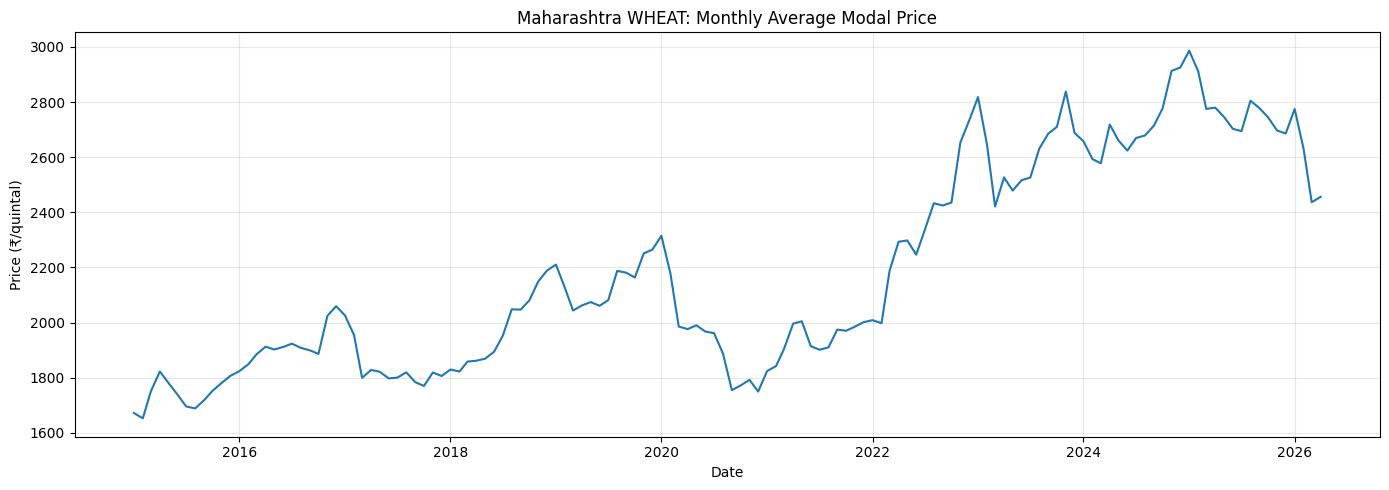

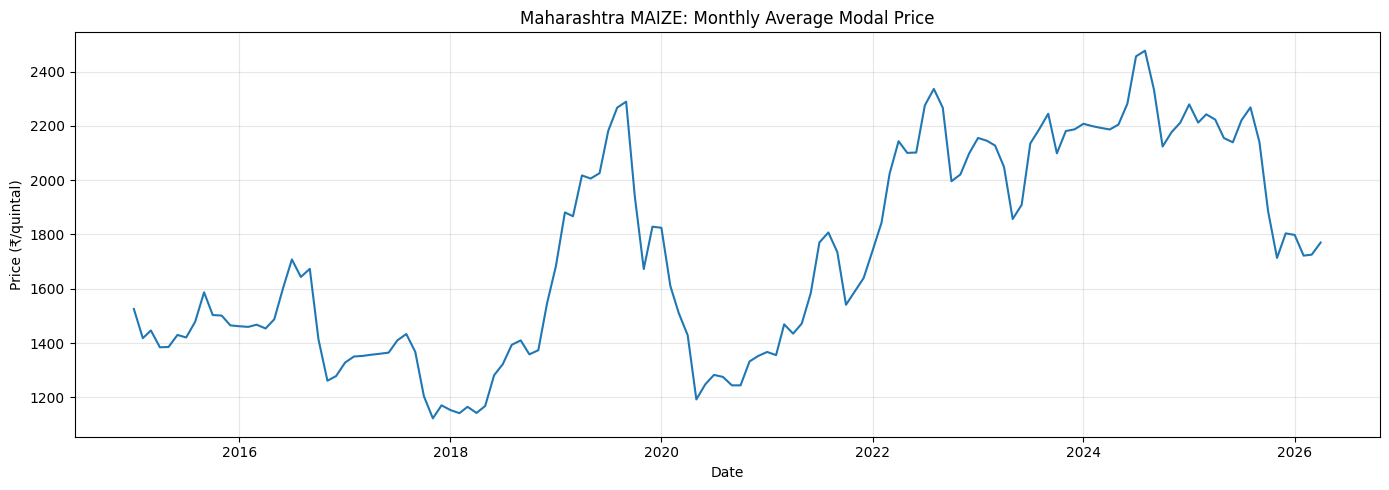

In [4]:

# Monthly average district prices

df["YearMonth"] = (
    df["Arrival_Date"].dt.to_period("M")
)

monthly = (
    df.groupby(["Commodity", "YearMonth"])
    ["district_modal_price"]
    .mean()
    .reset_index()
)

monthly["YearMonth"] = (
    monthly["YearMonth"].dt.to_timestamp()
)

for commodity in ["WHEAT", "MAIZE"]:

    subset = monthly[
        monthly["Commodity"] == commodity
    ]

    plt.figure(figsize=(14, 5))

    plt.plot(
        subset["YearMonth"],
        subset["district_modal_price"]
    )

    plt.title(
        f"Maharashtra {commodity}: Monthly Average Modal Price"
    )

    plt.xlabel("Date")
    plt.ylabel("Price (₹/quintal)")

    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


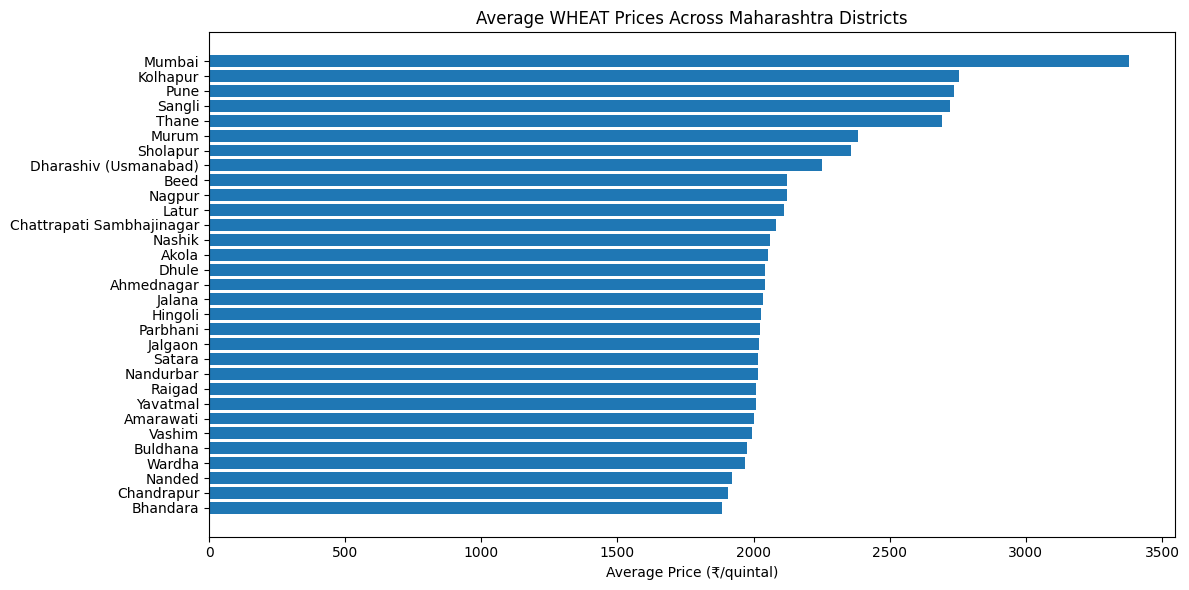

,Commodity,District,Average_Price,Median_Price,Price_SD,Min_Price,Max_Price,Observations
43,WHEAT,Mumbai,3379.471270,3200.000000,642.482635,2000.000000,4850.000000,1984
41,WHEAT,Kolhapur,2752.946237,2700.000000,256.550588,2000.000000,4200.000000,744
50,WHEAT,Pune,2737.482822,2583.333333,936.307693,1300.000000,5250.000000,3374
52,WHEAT,Sangli,2722.113958,2500.000000,494.599361,1900.000000,4500.000000,2615
55,WHEAT,Thane,2691.698283,2625.000000,484.036539,1400.000000,4500.000000,3286
44,WHEAT,Murum,2383.815068,2201.000000,723.485048,1300.000000,4401.000000,584
54,WHEAT,Sholapur,2358.891931,2322.400000,432.832543,1100.000000,4300.000000,3211
36,WHEAT,Dharashiv (Usmanabad),2250.132869,2250.000000,585.150337,1200.000000,5300.000000,2546
31,WHEAT,Beed,2123.454963,2023.500000,430.811908,1200.000000,3654.000000,3172
45,WHEAT,Nagpur,2121.747157,2025.000000,406.244308,945.000000,4474.333333,3640


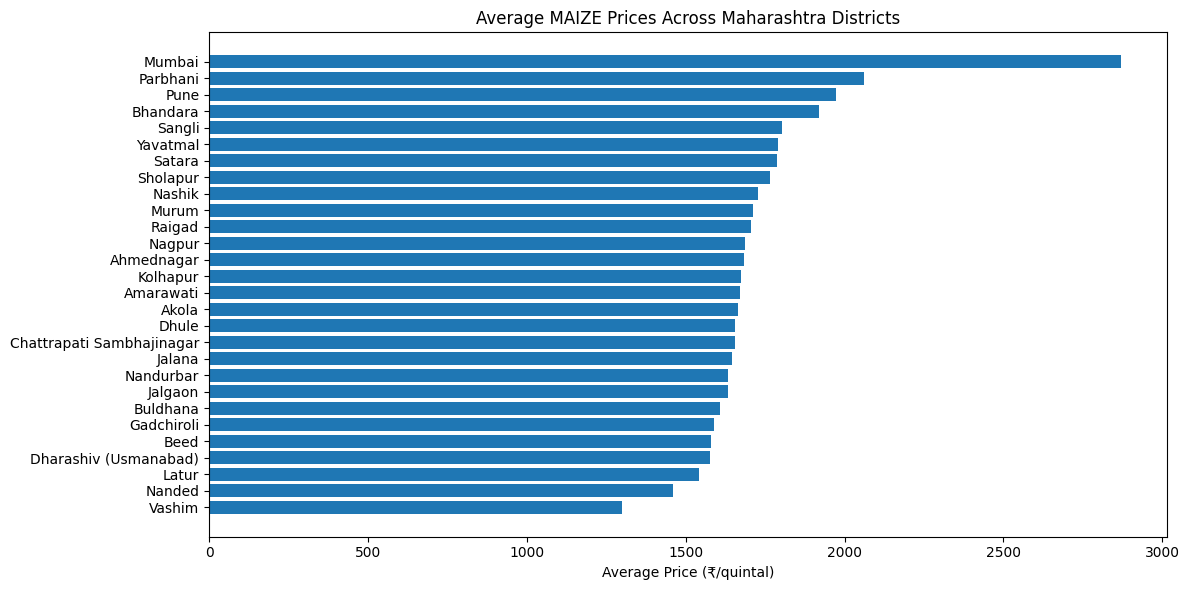

,Commodity,District,Average_Price,Median_Price,Price_SD,Min_Price,Max_Price,Observations
14,MAIZE,Mumbai,2871.251630,3000.000000,669.088327,350.0,10000.000000,1534
20,MAIZE,Parbhani,2060.100000,1475.500000,1213.250130,1399.0,4400.000000,10
21,MAIZE,Pune,1972.891304,1987.500000,483.477601,1000.0,4500.000000,3285
4,MAIZE,Bhandara,1918.333333,1950.000000,235.831861,1500.0,2160.000000,6
23,MAIZE,Sangli,1802.505368,1660.000000,368.684351,1310.0,2920.000000,1661
27,MAIZE,Yavatmal,1789.647059,1765.000000,381.352354,1100.0,2680.000000,17
24,MAIZE,Satara,1788.578882,1660.000000,386.657800,1200.0,2800.000000,805
25,MAIZE,Sholapur,1764.897618,1736.916667,411.184223,800.0,5600.000000,2826
19,MAIZE,Nashik,1727.961911,1683.750000,416.851196,1000.0,7871.000000,3166
15,MAIZE,Murum,1710.602273,1655.500000,356.884718,1122.0,2500.000000,88


In [5]:

district_summary = (
    df.groupby(["Commodity", "District"])
    .agg(
        Average_Price=("district_modal_price", "mean"),
        Median_Price=("district_modal_price", "median"),
        Price_SD=("district_modal_price", "std"),
        Min_Price=("district_modal_price", "min"),
        Max_Price=("district_modal_price", "max"),
        Observations=("district_modal_price", "count")
    )
    .reset_index()
)

for commodity in ["WHEAT", "MAIZE"]:

    result = (
        district_summary[
            district_summary["Commodity"] == commodity
        ]
        .sort_values("Average_Price", ascending=False)
    )

    plt.figure(figsize=(12, 6))

    plt.barh(
        result["District"],
        result["Average_Price"]
    )

    plt.title(
        f"Average {commodity} Prices Across Maharashtra Districts"
    )

    plt.xlabel("Average Price (₹/quintal)")
    plt.gca().invert_yaxis()

    plt.tight_layout()
    plt.show()

    display(result)


In [6]:

# Sort before creating lag features
df = df.sort_values(
    ["Commodity", "District", "Arrival_Date"]
).copy()

group = df.groupby(
    ["Commodity", "District"]
)["district_modal_price"]

# Historical prices
for lag in [1, 7, 14, 30]:
    df[f"Price_Lag_{lag}"] = group.shift(lag)

# Rolling averages
for window in [7, 14, 30]:
    df[f"Rolling_Mean_{window}"] = (
        df.groupby(["Commodity", "District"])
        ["district_modal_price"]
        .transform(
            lambda x: x.shift(1).rolling(window).mean()
        )
    )

# Rolling volatility
df["Rolling_SD_7"] = (
    df.groupby(["Commodity", "District"])
    ["district_modal_price"]
    .transform(
        lambda x: x.shift(1).rolling(7).std()
    )
)

# Percentage change
df["Price_Change_1D"] = (
    df.groupby(["Commodity", "District"])
    ["district_modal_price"]
    .transform(lambda x: x.pct_change())
)

# Calendar features
df["Month"] = df["Arrival_Date"].dt.month
df["Quarter"] = df["Arrival_Date"].dt.quarter
df["DayOfWeek"] = df["Arrival_Date"].dt.dayofweek

# Save feature dataset
df.to_parquet(
    OUTPUT_DIR / "maharashtra_price_features.parquet",
    index=False
)

print("Feature engineering completed.")
display(df.head(10))


Feature engineering completed.


,Arrival_Date,State,District,Commodity,district_modal_price,district_avg_min_price,district_avg_max_price,mandi_count,mandi_price_sd,lowest_mandi_modal_price,...,YearMonth,Price_Lag_1,Price_Lag_7,Price_Lag_14,Price_Lag_30,Rolling_Mean_7,Rolling_Mean_14,Rolling_Mean_30,Rolling_SD_7,Price_Change_1D
0,2015-01-03,Maharashtra,Ahmednagar,MAIZE,1826.0,1826.0,1826.0,1,NaN,1826.0,...,2015-01,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2015-01-04,Maharashtra,Ahmednagar,MAIZE,1310.0,1310.0,1310.0,1,NaN,1310.0,...,2015-01,1826.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.282585
2,2015-01-12,Maharashtra,Ahmednagar,MAIZE,1325.0,1325.0,1325.0,1,NaN,1325.0,...,2015-01,1310.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.011450
3,2015-01-21,Maharashtra,Ahmednagar,MAIZE,1310.0,1310.0,1310.0,1,NaN,1310.0,...,2015-01,1325.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-0.011321
4,2015-01-30,Maharashtra,Ahmednagar,MAIZE,1310.0,1310.0,1310.0,1,NaN,1310.0,...,2015-01,1310.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000
5,2015-02-06,Maharashtra,Ahmednagar,MAIZE,1310.0,1310.0,1310.0,1,NaN,1310.0,...,2015-02,1310.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000
6,2015-02-07,Maharashtra,Ahmednagar,MAIZE,1740.0,1740.0,1740.0,1,NaN,1740.0,...,2015-02,1310.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.328244
7,2015-02-09,Maharashtra,Ahmednagar,MAIZE,1310.0,1310.0,1310.0,1,NaN,1310.0,...,2015-02,1740.0,1826.0,NaN,NaN,1447.285714,NaN,NaN,230.741352,-0.247126
8,2015-02-10,Maharashtra,Ahmednagar,MAIZE,1310.0,1310.0,1310.0,1,NaN,1310.0,...,2015-02,1310.0,1310.0,NaN,NaN,1373.571429,NaN,NaN,161.676485,0.000000
9,2015-02-13,Maharashtra,Ahmednagar,MAIZE,1310.0,1310.0,1310.0,1,NaN,1310.0,...,2015-02,1310.0,1325.0,NaN,NaN,1373.571429,NaN,NaN,161.676485,0.000000
